## XGBoost Regression with California Housing Data

**Gradient Boosting** builds a model one tree at a time. Each new tree tries to improve the predictions made by the trees already built.

For regression, the model commonly minimizes **mean squared error**


The error for each observation can be written as:

$$
\text{Residual}_i = y_i - \hat{y}_i
$$

where:

- $y_i$ is the actual value.
- $\hat{y}_i$ is the predicted value.

At each stage, a new tree is added to the current model:

$$
F_{t+1}(x) = F_t(x) + \eta \cdot h_t(x)
$$

where:

- $F_t(x)$ is the current model score.
- $h_t(x)$ is the new decision tree.
- $\eta$ is the learning rate

**Simple interpretation:** Each new tree tries to reduce the prediction errors made by the current model.

---

## What is XGBoost?

**XGBoost (Extreme Gradient Boosting)** is an efficient implementation of gradient boosting.

It includes several useful improvements:

- **Regularization**: Controls model complexity and helps reduce overfitting.
- **Parallelization**: Speeds up calculations used to find the best tree splits.
- **Missing Values**: Learns which branch missing values should follow.
- **Tree Pruning**: Removes branches that do not improve the model enough.
- **Column Subsampling**: Allows each tree to use a selection of features.

For simplicity, we leave these settings at their default values and focus on tuning three key hyperparameters:

- `n_estimators`: Number of boosting rounds.
- `max_depth`: Maximum depth of a tree.
- `learning_rate`: Step size shrinkage used to prevent overfitting.

---

## Role of the Learning Rate 

The **learning rate** controls how much each new tree changes the model.

| Learning Rate | Behavior                                                   |
|---------------|------------------------------------------------------------|
| Larger ($ \eta \approx 0.3 $)  | Learns faster and usually needs fewer trees, but may overfit                             |
| Smaller ($ \eta \approx 0.01 $) | Learns more gradually and usually needs more trees |

The learning rate and number of trees should be considered together:

- **Smaller learning rate → usually more trees**
- **Larger learning rate → usually fewer trees**

---

## Evaluating the Regression Model

Regression models can be evaluated using:

- **Mean Absolute Error (MAE):** Average size of the prediction errors.
- **Root Mean Squared Error (RMSE):** Gives more weight to large errors.
- **$R^2$ score:** Measures how much variation in the target is explained by the model.

---

## SHAP

We’ll evaluate model performance and interpret it using SHAP (SHapley Additive exPlanations).

---

## Summary
Gradient Boosting adds trees sequentially to reduce prediction errors. XGBoost makes this process more efficient and adds controls that can reduce overfitting.

For this regression example, XGBoost predicts a numerical value: the median house value.


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


## 🔧 Hyperparameter Tuning: `n_estimators`

The `n_estimators` parameter defines the number of boosting rounds (trees). Increasing it can improve performance but might lead to overfitting.


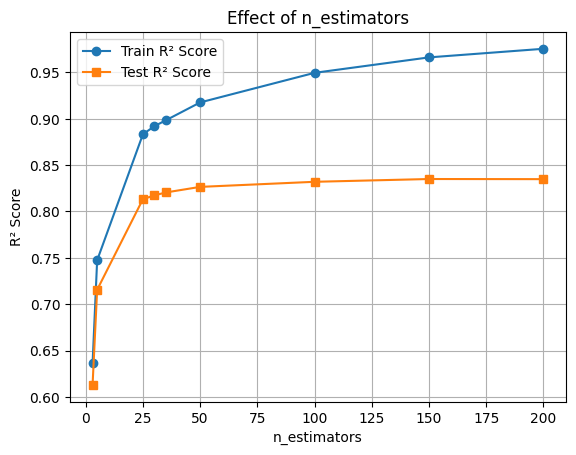

In [15]:
estimators = [3, 5, 25, 30, 35, 50, 100, 150, 200]
train_scores, test_scores = [], []

for n in estimators:
    clf = XGBRegressor(n_estimators=n, eval_metric='rmse')
    clf.fit(X_train, y_train)
    train_scores.append(r2_score(y_train, clf.predict(X_train)))
    test_scores.append(r2_score(y_test, clf.predict(X_test)))

plt.plot(estimators, train_scores, marker='o', label='Train R² Score')
plt.plot(estimators, test_scores, marker='s', label='Test R² Score')
plt.xlabel('n_estimators')
plt.ylabel('R² Score')
plt.title('Effect of n_estimators')
plt.legend()
plt.grid(True)
plt.show()


## 🔧 Hyperparameter Tuning: `max_depth`

The `max_depth` parameter controls the complexity of each tree. Deeper trees can learn more complex patterns but may overfit.


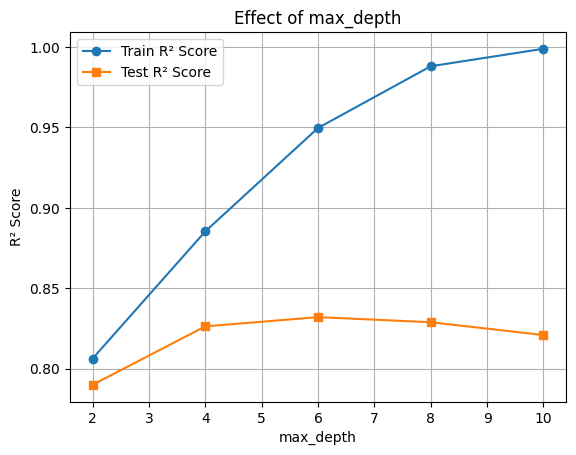

In [16]:
depths = [2, 4, 6, 8, 10]
train_scores, test_scores = [], []

for d in depths:
    clf = XGBRegressor(max_depth=d, eval_metric='rmse')
    clf.fit(X_train, y_train)
    train_scores.append(r2_score(y_train, clf.predict(X_train)))
    test_scores.append(r2_score(y_test, clf.predict(X_test)))

plt.plot(depths, train_scores, marker='o', label='Train R² Score')
plt.plot(depths, test_scores, marker='s', label='Test R² Score')
plt.xlabel('max_depth')
plt.ylabel('R² Score')
plt.title('Effect of max_depth')
plt.legend()
plt.grid(True)
plt.show()


## 🔧 Hyperparameter Tuning: `learning_rate`

The `learning_rate` parameter shrinks the contribution of each tree. Lower values require more trees but improve generalization.


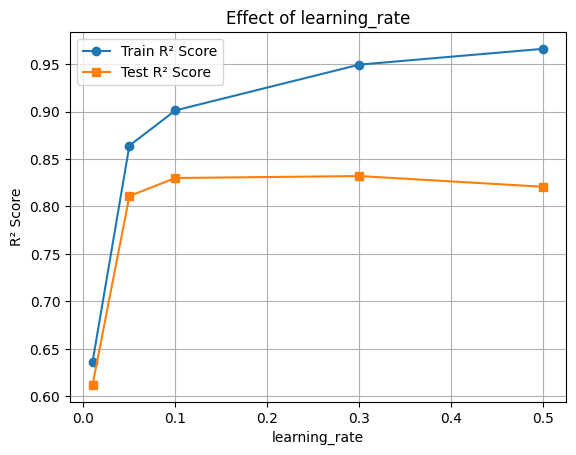

In [17]:
rates = [0.01, 0.05, 0.1, 0.3, 0.5]
train_scores, test_scores = [], []

for rate in rates:
    clf = XGBRegressor(learning_rate=rate, eval_metric='rmse')
    clf.fit(X_train, y_train)
    train_scores.append(r2_score(y_train, clf.predict(X_train)))
    test_scores.append(r2_score(y_test, clf.predict(X_test)))

plt.plot(rates, train_scores, marker='o', label='Train R² Score')
plt.plot(rates, test_scores, marker='s', label='Test R² Score')
plt.xlabel('learning_rate')
plt.ylabel('R² Score')
plt.title('Effect of learning_rate')
plt.legend()
plt.grid(True)
plt.show()



## Evaluating the Regression Model - R²

R² score measures how much variation in the target is explained by the model.

In [18]:
final_clf = XGBRegressor(
                         n_estimators=150,
                         max_depth=6,
                         learning_rate=0.1,
                         eval_metric='rmse')
final_clf.fit(X_train, y_train)
y_pred = final_clf.predict(X_test)

# R² Score
train_acc = final_clf.score(X_train, y_train)
test_acc = final_clf.score(X_test, y_test)

print(f"Train R² Score: {train_acc:.3f}")
print(f"Test R² Score: {test_acc:.3f}")

Train R² Score: 0.922
Test R² Score: 0.838


## 🧠 Feature Importance with SHAP

We'll use SHAP (SHapley Additive exPlanations) to understand how different features contribute to the model's predictions.

This helps us:
- Identify the most influential features
- Understand direction and magnitude of impact


### 📊 Interpreting the SHAP Summary Plot

The SHAP summary plot visualizes how each feature contributes to the model's output across all samples. Here's what each component means:

| Element                      | Description                                                                                      |
|-----------------------------|--------------------------------------------------------------------------------------------------|
| **Y-axis (Feature Names)**  | Features are sorted by overall importance (top = most important).                              |
| **X-axis (SHAP value)**     | The impact of that feature on the model's prediction.                                           |
| **Each Dot**                | A single row/sample in the dataset.                                                             |
| **Color (Dot Hue)**         | The feature value for that sample — red = high, blue = low.                                    |
| **Direction of SHAP Value**| Positive SHAP value pushes the prediction toward the positive class (e.g., "disease" class).    |
|                             | Negative SHAP value pushes it toward the negative class (e.g., "no disease").                   |

**🧠 Example Interpretation:**  
If the “Age” feature has mostly red dots (high values) with positive SHAP values, it means higher ages are pushing predictions toward the positive class.


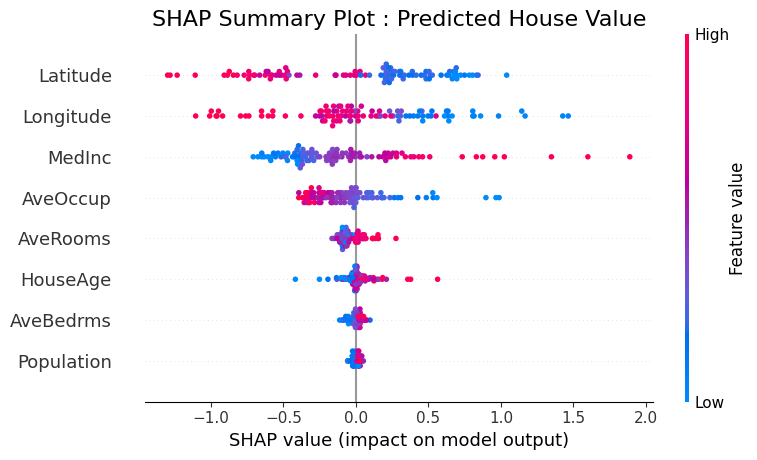

In [19]:
import matplotlib.pyplot as plt
import shap

# Select 100 housing records
X_sample = X_test.head(100)

# Explain the regression model
explainer = shap.TreeExplainer(final_clf)
shap_values = explainer.shap_values(X_sample)

# Increase figure size and adjust layout
plt.figure(figsize=(10, 6))

shap.summary_plot(shap_values, X_sample, show=False)
plt.title("SHAP Summary Plot : Predicted House Value", fontsize=16)
plt.tight_layout()
plt.show()
